# Kafe TETI (Kaftet) - Data Cleaning & Integration

**Dataset:** `Struk_Indogrosir_restock_18_April_2026 (2).xlsx` - inventory restocking
receipts (struk belanja) from **Indogrosir Yogyakarta**, recorded by Kafe TETI for
its stock purchasing.

## 1. Project Overview

### Background
Kafe TETI restocks its snack & beverage inventory at Indogrosir. Each shopping trip
produces a receipt that has been transcribed into one Excel sheet. The workbook holds
**five sheets** of receipts. Although they share the same basic layout, they differ in:

- column names and the set of trailing columns (`sisa`/`rusak` vs `Untung` vs `Untung/pcs`),
- date formats and whether a transaction number or a time is recorded,
- **monetary scale** - one sheet records prices in thousands of rupiah as small decimals
  (e.g. `16.9`) while the others use full rupiah (e.g. `20000`),
- missing-value conventions (`-`, `0`, blank, `#DIV/0!`),
- and the number of metadata / summary rows that are **not** item-level data.

### Objectives
1. **Clean** each sheet: standardise column names, types, whitespace, and missing values.
2. **Separate** real item rows from receipt metadata and payment-summary rows.
3. **Integrate** all sheets into one tidy table where *one row = one item in one transaction*.
4. **Detect and document anomalies** (date mismatches, monetary-scale differences,
   ambiguous columns) **without silently "fixing" them**.
5. **Validate** the result and **export** clean files plus an auditable cleaning log.

### Libraries
- `pandas` - tabular data loading & manipulation
- `numpy` - numeric helpers / NaN handling
- `matplotlib` - a couple of distribution plots to explain anomalies
- `re`, `pathlib`, `datetime` - parsing receipt metadata and file handling

### Workflow (sections of this notebook)
1. Project overview *(this cell)*
2. Import libraries & load data
3. Initial data exploration
4. Data cleaning *(with an editable column mapping)*
5. Anomaly detection & validation
6. Data integration
7. Final data-quality checks
8. Export results

> **Design principle:** the pipeline **preserves original values** and records every
> transformation in a cleaning log. Decisions that need a human (e.g. which date is
> authoritative) are surfaced in tables, not auto-corrected.

## 2. Import Libraries and Load Data

The source file path is stored in a **single variable** (`SOURCE_FILE`) so it is easy
to change. All sheets are read with `header=None` because the real header is **not** on
the first row - rows 0-3 hold store/receipt metadata.

In [3]:
import re
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", category=UserWarning)  # quiet openpyxl style warnings

# --- Edit these paths if your file or output location changes -------------------------
SOURCE_FILE = Path("Struk_Indogrosir_restock_18_April_2026 (2).xlsx")
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

print("pandas :", pd.__version__)
print("numpy  :", np.__version__)
print("source :", SOURCE_FILE.resolve())
print("exists :", SOURCE_FILE.exists())

pandas : 2.2.3
numpy  : 2.1.3
source : /content/Struk_Indogrosir_restock_18_April_2026 (2).xlsx
exists : True


In [4]:
# Read every sheet WITHOUT a header so we can see the true row structure.
# `sheet_name=None` returns a dict {sheet_name: DataFrame}.
raw_sheets = pd.read_excel(SOURCE_FILE, sheet_name=None, header=None)

sheet_names = list(raw_sheets.keys())
print(f"Found {len(sheet_names)} sheets:\n")
for name, df in raw_sheets.items():
    print(f"  - {name!r:<40} shape={df.shape}")

Found 5 sheets:

  - 'Struk Belanja (18-04-2026)'             shape=(53, 16)
  - 'struk belanja (19-08-2026)'             shape=(53, 14)
  - 'struk belanja (23-06-2026)'             shape=(29, 16)
  - 'struk belanja (04-09-2026)'             shape=(44, 14)
  - 'struk belanja (18-09-2026)'             shape=(62, 14)


In [5]:
# A single running log of every transformation / decision. Exported at the end.
cleaning_log = []

def log(step, sheet, detail):
    '''Record one transformation so the pipeline is auditable.'''
    cleaning_log.append({"step": step, "sheet": sheet, "detail": detail})

log("load", "ALL", f"Loaded {len(sheet_names)} sheets with header=None from {SOURCE_FILE.name}")
print("cleaning_log initialised.")

cleaning_log initialised.


## 3. Initial Data Exploration

We do **not** assume every row is an item. For each sheet we:

- look at the first and last rows (raw, no header),
- locate the **header row** (the one containing `Kode PLU` / `Nama Barang`),
- classify each row as `metadata` (rows above the header), `header`, `item`
  (numeric `No` + a PLU), or `summary` (totals / payment lines),
- count missing values and duplicates **on the item rows only**.

This classification is what lets us keep item data separate from summary rows.

In [6]:
def find_header_row(df):
    '''Return the index of the row that contains the item-table header.
    We detect it by the presence of the 'Kode PLU' and 'Nama Barang' labels.'''
    for i in range(min(15, len(df))):
        row_text = " ".join(str(v).lower() for v in df.iloc[i].tolist())
        if "kode plu" in row_text and "nama barang" in row_text:
            return i
    return None

header_rows = {name: find_header_row(df) for name, df in raw_sheets.items()}
header_rows

{'Struk Belanja (18-04-2026)': 4,
 'struk belanja (19-08-2026)': 4,
 'struk belanja (23-06-2026)': 4,
 'struk belanja (04-09-2026)': 4,
 'struk belanja (18-09-2026)': 4}

In [7]:
# Peek at the first 6 and last 4 raw rows of each sheet so the structure is visible.
for name, df in raw_sheets.items():
    print("=" * 90)
    print(f"SHEET: {name!r}   shape={df.shape}   header row index = {header_rows[name]}")
    print("-- first 6 rows --")
    display(df.head(6))
    print("-- last 4 rows --")
    display(df.tail(4))

SHEET: 'Struk Belanja (18-04-2026)'   shape=(53, 16)   header row index = 4
-- first 6 rows --


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,INDOGROSIR YOGYAKARTA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"Jl. Raya Magelang KM.6 Sleman, Yogyakarta | Ta...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Member: PALUPI FITRIA NINGRUM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,No,Kode PLU,Nama Barang,Qty,Harga Satuan (Rp),Diskon (Rp),Total Sebelum Diskon (Rp),Total Akhir (Rp),Total,Isi,Modal/pcs,Jual/pcs,Jual Total,NaN,sisa,rusak
5,1,1676583,DILAN CHOCO WAFFLE16,1,20000,-,20000,20000,NaN,12,1666.666667,2000,24000,NaN,3,0


-- last 4 rows --


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
49,ANDA HEMAT,NaN,NaN,NaN,NaN,NaN,Rp,57475,NaN,print,NaN,NaN,NaN,NaN,NaN,NaN
50,DPP (Dasar Pengenaan Pajak),NaN,NaN,NaN,NaN,NaN,Rp,612866,NaN,grab,NaN,11500,NaN,NaN,NaN,NaN
51,PPN (11%),NaN,NaN,NaN,NaN,NaN,Rp,73544,NaN,lakban,NaN,NaN,NaN,NaN,NaN,NaN
52,HARGA JUAL (Net),NaN,NaN,NaN,NaN,NaN,Rp,668581,NaN,KEUNTUNGAN,NaN,169475,NaN,NaN,NaN,NaN


SHEET: 'struk belanja (19-08-2026)'   shape=(53, 14)   header row index = 4
-- first 6 rows --


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,INDOGROSIR YOGYAKARTA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"Jl. Raya Magelang KM.6 Sleman, Yogyakarta | Ta...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Member: PALUPI FITRIA NINGRUM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,No,Kode PLU,Nama Barang,Qty,Harga Satuan (Rp),Diskon (Rp),Total Sebelum Diskon (Rp),Total Akhir (Rp),Total,Isi,Modal/pcs,Jual/pcs,Jual Total,Untung
5,1,1539712,BONCABE MK LV2 NC 27,1,17200,-,17200,17200,NaN,10,1720,2500,25000,780


... (10 outputs left out)

SHEET: 'struk belanja (18-09-2026)'   shape=(62, 14)   header row index = 4
-- first 6 rows --


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,INDOGROSIR YOGYAKARTA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"Jl. Raya Magelang KM.0 Sleman, Yogyakarta - Te...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Member: PALUPI FITRIA NINGRUM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,No,Kode PLU,Nama Barang,Qty,Harga Satuan (Rp),Diskon (Rp),Total Sebelum Diskon (Rp),Total Akhir (Rp),NaN,Isi,Modal/pcs,Jual/pcs,Jual Total,Untung/pcs
5,1,1571251,LAYS RMPT LAUT 10X13,1,16.9,1.6,16.9,15.3,NaN,10,1.53,2.5,25,9.7


-- last 4 rows --


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
58,NaN,PPN (12%),NaN,NaN,NaN,NaN,122.962,NaN,NaN,NaN,NaN,NaN,NaN,NaN
59,NaN,HARGA JUAL (Net),NaN,NaN,NaN,NaN,1.117.838,NaN,Ditranskrip dari struk,NaN,NaN,NaN,NaN,NaN
60,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
61,NaN,Keterangan: teks biru = input manual (boleh di...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
def classify_rows(df, header_idx):
    '''Label every row: metadata / header / item / summary / blank.
    An *item* row has a numeric running number in col 0 AND a PLU-like value in col 1.'''
    labels = []
    for i in range(len(df)):
        if header_idx is not None and i < header_idx:
            labels.append("metadata")
            continue
        if i == header_idx:
            labels.append("header")
            continue
        c0, c1 = df.iat[i, 0], df.iat[i, 1]
        if pd.isna(c0) and pd.isna(c1):
            labels.append("blank")
            continue
        # numeric running No + non-empty PLU => item row
        no_is_num = pd.to_numeric(pd.Series([c0]), errors="coerce").notna().iat[0]
        plu_present = not pd.isna(c1)
        labels.append("item" if (no_is_num and plu_present) else "summary")
    return pd.Series(labels, index=df.index)

row_kinds = {name: classify_rows(df, header_rows[name]) for name, df in raw_sheets.items()}

# Summary of how many rows of each kind per sheet.
kind_summary = pd.DataFrame(
    {name: row_kinds[name].value_counts() for name in sheet_names}
).fillna(0).astype(int).T
kind_summary.index.name = "sheet"
kind_summary

,blank,header,item,metadata,summary
sheet,,,,,
Struk Belanja (18-04-2026),1,1,40,4,7
struk belanja (19-08-2026),1,1,40,4,7
struk belanja (23-06-2026),0,1,22,4,2
struk belanja (04-09-2026),1,1,29,4,9
struk belanja (18-09-2026),5,1,43,4,9


In [9]:
# Quick missing-value + duplicate scan on the RAW item rows of each sheet
# (using the detected header as column names), before any cleaning.
initial_report = []
for name, df in raw_sheets.items():
    h = header_rows[name]
    items_mask = row_kinds[name] == "item"
    n_items = int(items_mask.sum())
    tmp = df[items_mask].copy()
    if h is not None:
        tmp.columns = df.iloc[h].tolist()
    n_dupes = int(tmp.duplicated().sum())
    initial_report.append({
        "sheet": name,
        "total_rows": len(df),
        "n_cols": df.shape[1],
        "item_rows": n_items,
        "duplicate_item_rows": n_dupes,
    })

initial_summary = pd.DataFrame(initial_report).set_index("sheet")
print("Initial condition of the dataset (before cleaning):")
initial_summary

Initial condition of the dataset (before cleaning):


,total_rows,n_cols,item_rows,duplicate_item_rows
sheet,,,,
Struk Belanja (18-04-2026),53,16,40,0
struk belanja (19-08-2026),53,14,40,0
struk belanja (23-06-2026),29,16,22,0
struk belanja (04-09-2026),44,14,29,0
struk belanja (18-09-2026),62,14,43,0


## 4. Data Cleaning

Cleaning is broken into small, commented steps. The centrepiece is an **explicit column
mapping** - a plain dictionary you can edit if you find different column names in a new
export. Every raw header label is mapped to a standard `snake_case` name.

### What each step does
1. **Column mapping** - raw label -> standard snake_case name (editable dictionary).
2. **Slice item rows** using the row classification from section 3.
3. **Rename & standardise columns**; strip whitespace from text.
4. **Types**: PLU -> string, numeric columns -> numeric (handle `-`, `0`, `#DIV/0!`).
5. **Missing values** are *kept as NaN* - we do **not** blanket-fill with zero.
6. **Transaction metadata** (date, time, transaction no., member) extracted from rows 1-2.
7. Add **`source_sheet`** and **`source_row`** (original Excel row index, 1-based).
8. Every step appended to `cleaning_log`.

In [10]:
# ---------------------------------------------------------------------------
# EDITABLE COLUMN MAPPING
# Raw header label (as printed in section 3)  ->  standard snake_case name.
# If a future export uses different labels, edit the LEFT-hand strings here.
# ---------------------------------------------------------------------------
COLUMN_MAPPING = {
    "No": "line_no",
    "Kode PLU": "plu_code",
    "Nama Barang": "item_name",
    "Qty": "qty",
    "Harga Satuan (Rp)": "unit_price",
    "Diskon (Rp)": "discount",
    "Total Sebelum Diskon (Rp)": "total_before_discount",
    "Total Akhir (Rp)": "total_after_discount",
    "Total": "total_raw",          # almost always empty in the source
    "Isi": "isi",                  # units per pack (pcs per carton)
    "Modal/pcs": "cost_per_pcs",   # cost price per piece
    "Jual/pcs": "sell_per_pcs",    # selling price per piece
    "Jual Total": "sell_total",    # selling value of the whole purchase
    "Untung": "profit",            # profit for the line (some sheets)
    "Untung/pcs": "profit_per_pcs",# profit per piece (one sheet)
    "sisa": "sisa",                # leftover stock noted manually
    "rusak": "rusak",              # damaged units noted manually
}

# Columns we treat as monetary / numeric (used for type coercion & anomaly checks).
NUMERIC_COLS = [
    "line_no", "qty", "unit_price", "discount",
    "total_before_discount", "total_after_discount", "total_raw",
    "isi", "cost_per_pcs", "sell_per_pcs", "sell_total",
    "profit", "profit_per_pcs", "sisa", "rusak",
]
# Tokens that mean "missing / not-a-number" in this dataset.
NA_TOKENS = {"-", "", "nan", "#div/0!", "#value!", "#ref!", "#n/a", "na", "none"}
print("Column mapping defines", len(COLUMN_MAPPING), "known columns.")

Column mapping defines 17 known columns.


In [11]:
def to_number(x):
    '''Coerce a messy cell to a float.
    Handles '-', blanks, '#DIV/0!', and dot-thousand separators like '1.240.800'.
    Returns np.nan when the value is genuinely missing/invalid (NO silent zero-fill).'''
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    if s.lower() in NA_TOKENS:
        return np.nan
    # '1.240.800' -> dot thousand separators (2+ dots, or dot groups of 3)
    if re.fullmatch(r"\d{1,3}(\.\d{3})+", s):
        s = s.replace(".", "")
    s = s.replace(",", "")  # strip stray thousands commas
    try:
        return float(s)
    except ValueError:
        return np.nan

In [12]:
def extract_metadata(df):
    '''Pull receipt metadata from the top rows.
    Row 1 typically holds 'Tanggal: ...' and 'No. Transaksi: ...' or 'Waktu: ...';
    row 2 holds 'Member: ...'. Returns raw strings only - no reformatting.'''
    meta = {"receipt_date_raw": np.nan, "receipt_time_raw": np.nan,
            "transaction_no": np.nan, "member": np.nan}
    top_text = " | ".join(
        str(v) for i in range(min(4, len(df))) for v in df.iloc[i].tolist()
        if not pd.isna(v)
    )
    m = re.search(r"Tanggal:\s*([0-9]{2}-[0-9]{2}-[0-9]{2,4})", top_text)
    if m:
        meta["receipt_date_raw"] = m.group(1)
    m = re.search(r"(\d{2}:\d{2}:\d{2})", top_text)
    if m:
        meta["receipt_time_raw"] = m.group(1)
    m = re.search(r"No\.?\s*Transaksi:\s*([^\s|]+)", top_text)
    if m:
        meta["transaction_no"] = m.group(1)
    m = re.search(r"Member:\s*([^|]+?)\s*(?:\||$)", top_text)
    if m:
        meta["member"] = m.group(1).strip()
    return meta

In [13]:
def clean_sheet(name, df, header_idx, kinds):
    '''Turn one raw sheet into a tidy item-level DataFrame.
    Keeps NaNs, records transformations, and tags source_sheet / source_row.'''
    # 1. Slice only the item rows identified in section 3.
    item_mask = kinds == "item"
    items = df[item_mask].copy()

    # 2. Apply the detected header, then map to snake_case.
    raw_header = [str(c).strip() for c in df.iloc[header_idx].tolist()]
    items.columns = raw_header
    # Keep only columns we know about; warn about any unmapped non-empty label.
    unmapped = [c for c in raw_header if c not in COLUMN_MAPPING and c.lower() != "nan"]
    if unmapped:
        log("unmapped_columns", name, f"Unmapped labels ignored: {unmapped}")
    keep = [c for c in raw_header if c in COLUMN_MAPPING]
    items = items[keep].rename(columns=COLUMN_MAPPING)

    # 3. source_row = original Excel row number (1-based: +1 for header offset).
    items["source_row"] = items.index + 1
    items["source_sheet"] = name

    # 4. Strip whitespace from text columns.
    for col in ("item_name", "plu_code"):
        if col in items:
            items[col] = items[col].astype(str).str.strip()

    # 5. PLU -> clean string (drop trailing '.0' that Excel may add to numbers).
    if "plu_code" in items:
        items["plu_code"] = (
            items["plu_code"].str.replace(r"\.0$", "", regex=True).replace("nan", np.nan)
        )

    # 6. Numeric coercion (keeps NaN for '-', blanks, '#DIV/0!').
    for col in NUMERIC_COLS:
        if col in items:
            items[col] = items[col].map(to_number)

    # 7. Attach receipt metadata (same for every item row of the sheet).
    meta = extract_metadata(df)
    for k, v in meta.items():
        items[k] = v

    log("clean_sheet", name,
        f"{len(items)} item rows; cols={list(items.columns)}; meta={meta}")
    return items

cleaned = {
    name: clean_sheet(name, raw_sheets[name], header_rows[name], row_kinds[name])
    for name in sheet_names
}

for name, df in cleaned.items():
    print(f"{name!r:<40} -> {df.shape[0]} items, {df.shape[1]} cols")

'Struk Belanja (18-04-2026)'             -> 40 items, 21 cols
'struk belanja (19-08-2026)'             -> 40 items, 20 cols
'struk belanja (23-06-2026)'             -> 22 items, 21 cols
'struk belanja (04-09-2026)'             -> 29 items, 20 cols
'struk belanja (18-09-2026)'             -> 43 items, 19 cols


In [14]:
cleaned["Struk Belanja (18-04-2026)"].head()

,line_no,plu_code,item_name,qty,unit_price,discount,total_before_discount,total_after_discount,total_raw,isi,cost_per_pcs,sell_per_pcs,sell_total,sisa,rusak,source_row,source_sheet,receipt_date_raw,receipt_time_raw,transaction_no,member
5,1.0,1676583,DILAN CHOCO WAFFLE16,1.0,20000.0,NaN,20000.0,20000.0,NaN,12.0,1666.666667,2000.0,24000.0,3.0,0.0,6,Struk Belanja (18-04-2026),18-04-2026,NaN,v7946.004.130.05.00012,PALUPI FITRIA NINGRUM
6,2.0,1833871,ROMA WFR SPRSTAR250G,1.0,19500.0,NaN,19500.0,19500.0,NaN,20.0,975.000000,1000.0,20000.0,0.0,0.0,7,Struk Belanja (18-04-2026),18-04-2026,NaN,v7946.004.130.05.00012,PALUPI FITRIA NINGRUM
7,3.0,1546073,DILAN CHOCO CARAML23,1.0,20000.0,NaN,20000.0,20000.0,NaN,12.0,1666.666667,2000.0,24000.0,0.0,0.0,8,Struk Belanja (18-04-2026),18-04-2026,NaN,v7946.004.130.05.00012,PALUPI FITRIA NINGRUM
8,4.0,1666303,FULLO WFR VNLA 14G,1.0,22000.0,2000.0,22000.0,20000.0,NaN,24.0,833.333333,1000.0,24000.0,13.0,0.0,9,Struk Belanja (18-04-2026),18-04-2026,NaN,v7946.004.130.05.00012,PALUPI FITRIA NINGRUM
9,5.0,1340773,RICHEESE WFR ROL KJ6,1.0,8900.0,NaN,8900.0,8900.0,NaN,20.0,445.000000,500.0,10000.0,0.0,0.0,10,Struk Belanja (18-04-2026),18-04-2026,NaN,v7946.004.130.05.00012,PALUPI FITRIA NINGRUM


## 5. Anomaly Detection and Validation

We investigate (but deliberately do **not** auto-correct) the anomalies seen while
inspecting the file. Each check produces a table for **manual review**.

Anomalies covered:
- **A. Date mismatch** - sheet-name date vs the `Tanggal:` printed on the receipt.
- **B. Monetary scale** - one sheet records prices as small decimals (`16.9`) instead of
  full rupiah (`20000`). We flag it by the median `unit_price`, we do **not** rescale.
- **C. Column-meaning differences** - which sheets carry `profit`, `profit_per_pcs`,
  `sisa`/`rusak`, and whether `total_raw` is ever populated.
- **D. Invalid quantities / prices** - non-positive qty or price, NaN after coercion.
- **E. Potential duplicate transactions / items.**

Original values are preserved; decisions are documented in the cleaning log.

In [15]:
# --- A. Date mismatch: sheet-name date vs printed receipt date ----------------------
def date_from_sheet_name(name):
    m = re.search(r"(\d{1,2})-(\d{1,2})-(\d{2,4})", name)
    if not m:
        return np.nan
    d, mth, y = m.groups()
    y = ("20" + y) if len(y) == 2 else y
    return f"{int(d):02d}-{int(mth):02d}-{y}"

date_rows = []
for name, df in cleaned.items():
    sheet_date = date_from_sheet_name(name)
    receipt_date = df["receipt_date_raw"].iloc[0] if len(df) else np.nan
    txn = df["transaction_no"].iloc[0] if len(df) else np.nan
    date_rows.append({
        "sheet": name,
        "date_in_sheet_name": sheet_date,
        "receipt_date_raw": receipt_date,
        "transaction_no": txn,
        "mismatch": (pd.notna(sheet_date) and pd.notna(receipt_date)
                     and not str(receipt_date).startswith(str(sheet_date)[:5])),
    })
date_check = pd.DataFrame(date_rows)
for _, r in date_check[date_check["mismatch"]].iterrows():
    log("anomaly_date", r["sheet"],
        f"Sheet-name date {r['date_in_sheet_name']} != receipt date {r['receipt_date_raw']} (NOT auto-corrected)")
print("A. Date: sheet-name vs printed receipt date")
date_check

A. Date: sheet-name vs printed receipt date


,sheet,date_in_sheet_name,receipt_date_raw,transaction_no,mismatch
0,Struk Belanja (18-04-2026),18-04-2026,18-04-2026,v7946.004.130.05.00012,False
1,struk belanja (19-08-2026),19-08-2026,19-08-2026,NaN,False
2,struk belanja (23-06-2026),23-06-2026,23-06-2026,v7946.004.130.05.00012,False
3,struk belanja (04-09-2026),04-09-2026,04-09-26,v7966.004.139.07.00020,False
4,struk belanja (18-09-2026),18-09-2026,18-09-26,v7967.004.507.04.00018,False


In [16]:
# --- B. Monetary scale check -------------------------------------------------------
# If median unit_price is tiny (< 1000) the sheet is almost certainly in 'thousands'
# scale (e.g. 16.9 meaning Rp 16,900). We FLAG it; we do not multiply anything.
scale_rows = []
for name, df in cleaned.items():
    med = df["unit_price"].median()
    scale_rows.append({
        "sheet": name,
        "median_unit_price": round(med, 3) if pd.notna(med) else np.nan,
        "likely_scale": "thousands (decimals)" if pd.notna(med) and med < 1000 else "full rupiah",
    })
scale_check = pd.DataFrame(scale_rows)
for _, r in scale_check[scale_check["likely_scale"].str.startswith("thousands")].iterrows():
    log("anomaly_scale", r["sheet"],
        f"median unit_price={r['median_unit_price']} -> likely thousands scale; "
        "original values PRESERVED, not rescaled")
print("B. Monetary scale (median unit price per sheet)")
scale_check

B. Monetary scale (median unit price per sheet)


,sheet,median_unit_price,likely_scale
0,Struk Belanja (18-04-2026),14450.0,full rupiah
1,struk belanja (19-08-2026),17200.0,full rupiah
2,struk belanja (23-06-2026),19350.0,full rupiah
3,struk belanja (04-09-2026),17200.0,full rupiah
4,struk belanja (18-09-2026),17.5,thousands (decimals)


In [17]:
# --- C. Column-meaning differences across sheets -----------------------------------
col_presence = pd.DataFrame({
    name: {c: (c in df.columns and df[c].notna().any()) for c in
           ["total_raw", "profit", "profit_per_pcs", "sisa", "rusak",
            "cost_per_pcs", "sell_per_pcs", "sell_total", "isi"]}
    for name, df in cleaned.items()
}).T
col_presence.index.name = "sheet"
print("C. Which value columns actually carry data in each sheet (True = has values)")
col_presence

C. Which value columns actually carry data in each sheet (True = has values)


,total_raw,profit,profit_per_pcs,sisa,rusak,cost_per_pcs,sell_per_pcs,sell_total,isi
sheet,,,,,,,,,
Struk Belanja (18-04-2026),False,False,False,True,True,True,True,True,True
struk belanja (19-08-2026),False,True,False,False,False,True,True,True,True
struk belanja (23-06-2026),False,False,False,False,False,True,True,True,True
struk belanja (04-09-2026),False,True,False,False,False,True,True,True,True
struk belanja (18-09-2026),False,False,True,False,False,True,True,True,True


In [18]:
# --- D. Invalid quantity / price values --------------------------------------------
invalid_rows = []
for name, df in cleaned.items():
    bad = df[
        (df["qty"].isna()) | (df["qty"] <= 0) |
        (df["unit_price"].isna()) | (df["unit_price"] <= 0)
    ]
    for _, r in bad.iterrows():
        invalid_rows.append({
            "sheet": name, "source_row": r["source_row"],
            "item_name": r.get("item_name"), "qty": r["qty"],
            "unit_price": r["unit_price"],
        })
invalid_check = pd.DataFrame(invalid_rows)
log("anomaly_invalid_qty_price", "ALL", f"{len(invalid_check)} rows with non-positive/NaN qty or price")
print(f"D. Invalid qty/price rows: {len(invalid_check)}")
invalid_check

D. Invalid qty/price rows: 0


""


In [19]:
# --- E. Potential duplicates -------------------------------------------------------
# Duplicate ITEMS inside the same sheet (same PLU + qty + price) are flagged for review
# only - identical items in DIFFERENT transactions are legitimate and kept.
dup_rows = []
for name, df in cleaned.items():
    key = ["plu_code", "qty", "unit_price"]
    dups = df[df.duplicated(subset=key, keep=False)].sort_values(key)
    if len(dups):
        dup_rows.append(dups.assign(_sheet=name)[["_sheet", "source_row",
                        "plu_code", "item_name", "qty", "unit_price"]])
dup_check = pd.concat(dup_rows, ignore_index=True) if dup_rows else pd.DataFrame(
    columns=["_sheet", "source_row", "plu_code", "item_name", "qty", "unit_price"])
log("anomaly_within_sheet_dupes", "ALL",
    f"{len(dup_check)} item rows share PLU+qty+price within a sheet (review only, kept)")
print(f"E. Within-sheet potential duplicate items: {len(dup_check)}")
dup_check.head(20)

E. Within-sheet potential duplicate items: 0


,_sheet,source_row,plu_code,item_name,qty,unit_price


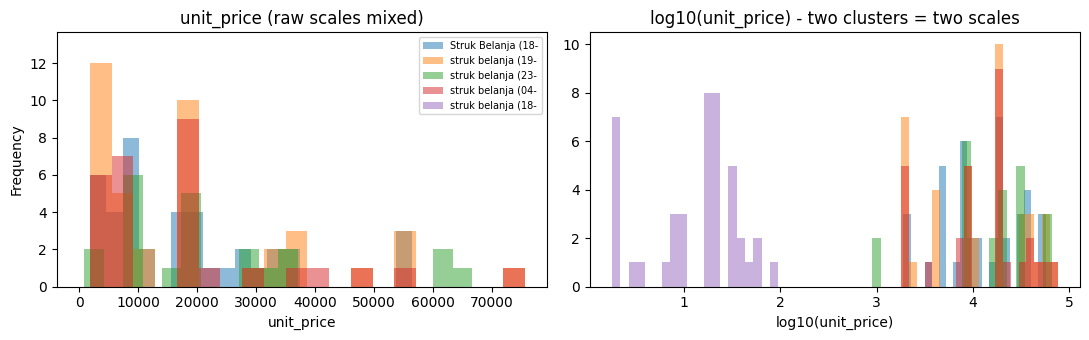

In [20]:
# --- Visual: unit-price distribution makes the scale anomaly obvious ---------------
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for name, df in cleaned.items():
    df["unit_price"].dropna().plot(kind="hist", bins=20, alpha=0.5, ax=ax[0], label=name[:18])
ax[0].set_title("unit_price (raw scales mixed)")
ax[0].set_xlabel("unit_price")
ax[0].legend(fontsize=7)

# log scale separates the 'thousands' sheet clearly
for name, df in cleaned.items():
    vals = df["unit_price"].dropna()
    vals = vals[vals > 0]
    ax[1].hist(np.log10(vals), bins=20, alpha=0.5, label=name[:18])
ax[1].set_title("log10(unit_price) - two clusters = two scales")
ax[1].set_xlabel("log10(unit_price)")
plt.tight_layout()
plt.show()

## 6. Data Integration

We standardise the column set across sheets and `concat` the **item rows** into one
table. Rules honoured:

- one row = **one item within one transaction** (no aggregation / merging of items),
- transaction metadata, PLU, name, qty, prices, discount and the extra columns are kept,
- `source_sheet` + `source_row` stay for traceability,
- no invented values - columns missing from a sheet simply stay `NaN`.

A `price_scale_flag` column is added (derived from section 5B) so downstream users know
which rows are in the "thousands" scale, **without** us altering the stored numbers.

In [21]:
# Canonical column order for the integrated table.
FINAL_COLUMNS = [
    # provenance
    "source_sheet", "source_row",
    # transaction metadata
    "receipt_date_raw", "receipt_time_raw", "transaction_no", "member",
    # item identity
    "line_no", "plu_code", "item_name",
    # transaction values
    "qty", "unit_price", "discount",
    "total_before_discount", "total_after_discount",
    # inventory / margin extras
    "isi", "cost_per_pcs", "sell_per_pcs", "sell_total",
    "profit", "profit_per_pcs", "sisa", "rusak",
    # scale flag from anomaly check B
    "price_scale_flag",
]

scale_lookup = dict(zip(scale_check["sheet"], scale_check["likely_scale"]))

standardised = []
for name, df in cleaned.items():
    tmp = df.copy()
    tmp["price_scale_flag"] = scale_lookup.get(name, "unknown")
    # add any missing canonical columns as NaN (no fabricated values)
    for col in FINAL_COLUMNS:
        if col not in tmp.columns:
            tmp[col] = np.nan
    standardised.append(tmp[FINAL_COLUMNS])

integrated = pd.concat(standardised, ignore_index=True)
log("integrate", "ALL", f"Concatenated to {integrated.shape[0]} item rows x {integrated.shape[1]} cols")
print("Integrated shape:", integrated.shape)
integrated.head()

Integrated shape: (174, 23)


,source_sheet,source_row,receipt_date_raw,receipt_time_raw,transaction_no,member,line_no,plu_code,item_name,qty,unit_price,discount,total_before_discount,total_after_discount,isi,cost_per_pcs,sell_per_pcs,sell_total,profit,profit_per_pcs,sisa,rusak,price_scale_flag
0,Struk Belanja (18-04-2026),6,18-04-2026,NaN,v7946.004.130.05.00012,PALUPI FITRIA NINGRUM,1.0,1676583,DILAN CHOCO WAFFLE16,1.0,20000.0,NaN,20000.0,20000.0,12.0,1666.666667,2000.0,24000.0,NaN,NaN,3.0,0.0,full rupiah
1,Struk Belanja (18-04-2026),7,18-04-2026,NaN,v7946.004.130.05.00012,PALUPI FITRIA NINGRUM,2.0,1833871,ROMA WFR SPRSTAR250G,1.0,19500.0,NaN,19500.0,19500.0,20.0,975.000000,1000.0,20000.0,NaN,NaN,0.0,0.0,full rupiah
2,Struk Belanja (18-04-2026),8,18-04-2026,NaN,v7946.004.130.05.00012,PALUPI FITRIA NINGRUM,3.0,1546073,DILAN CHOCO CARAML23,1.0,20000.0,NaN,20000.0,20000.0,12.0,1666.666667,2000.0,24000.0,NaN,NaN,0.0,0.0,full rupiah
3,Struk Belanja (18-04-2026),9,18-04-2026,NaN,v7946.004.130.05.00012,PALUPI FITRIA NINGRUM,4.0,1666303,FULLO WFR VNLA 14G,1.0,22000.0,2000.0,22000.0,20000.0,24.0,833.333333,1000.0,24000.0,NaN,NaN,13.0,0.0,full rupiah
4,Struk Belanja (18-04-2026),10,18-04-2026,NaN,v7946.004.130.05.00012,PALUPI FITRIA NINGRUM,5.0,1340773,RICHEESE WFR ROL KJ6,1.0,8900.0,NaN,8900.0,8900.0,20.0,445.000000,500.0,10000.0,NaN,NaN,0.0,0.0,full rupiah


In [22]:
# Row count per sheet in the integrated table (sanity check vs section 3).
integrated["source_sheet"].value_counts().rename("item_rows").to_frame()

,item_rows
source_sheet,
struk belanja (18-09-2026),43
Struk Belanja (18-04-2026),40
struk belanja (19-08-2026),40
struk belanja (04-09-2026),29
struk belanja (23-06-2026),22


## 7. Final Data Quality Checks

Before/after sizes, missing values, duplicates, dtypes, a price-consistency check, and
a few assertions on the final structure.

In [23]:
# Rows & columns before (raw item rows) vs after (cleaned) per sheet.
before_after = pd.DataFrame({
    "raw_total_rows": {n: raw_sheets[n].shape[0] for n in sheet_names},
    "raw_item_rows": {n: int((row_kinds[n] == "item").sum()) for n in sheet_names},
    "clean_item_rows": {n: cleaned[n].shape[0] for n in sheet_names},
    "clean_cols": {n: cleaned[n].shape[1] for n in sheet_names},
})
before_after.index.name = "sheet"
print(f"TOTAL integrated rows: {len(integrated)}")
before_after

TOTAL integrated rows: 174


,raw_total_rows,raw_item_rows,clean_item_rows,clean_cols
sheet,,,,
Struk Belanja (18-04-2026),53,40,40,21
struk belanja (19-08-2026),53,40,40,20
struk belanja (23-06-2026),29,22,22,21
struk belanja (04-09-2026),44,29,29,20
struk belanja (18-09-2026),62,43,43,19


In [24]:
# Missing values per column in the final table.
missing = integrated.isna().sum().to_frame("missing_count")
missing["missing_pct"] = (missing["missing_count"] / len(integrated) * 100).round(1)
missing

,missing_count,missing_pct
source_sheet,0,0.0
source_row,0,0.0
receipt_date_raw,0,0.0
receipt_time_raw,62,35.6
transaction_no,40,23.0
member,0,0.0
line_no,0,0.0
plu_code,0,0.0
item_name,0,0.0
qty,0,0.0


In [25]:
# Full-row duplicates in the integrated table (should be rare; kept, just reported).
n_full_dupes = int(integrated.duplicated().sum())
print("Exact full-row duplicates in integrated table:", n_full_dupes)

# Duplicate (sheet,row) provenance keys must be ZERO - that would mean a bug.
prov_dupes = int(integrated.duplicated(subset=["source_sheet", "source_row"]).sum())
print("Duplicate (source_sheet, source_row) keys:", prov_dupes)

Exact full-row duplicates in integrated table: 0
Duplicate (source_sheet, source_row) keys: 0


In [26]:
# Data types of all columns.
integrated.dtypes.to_frame("dtype")

,dtype
source_sheet,object
source_row,int64
receipt_date_raw,object
receipt_time_raw,object
transaction_no,object
member,object
line_no,float64
plu_code,object
item_name,object
qty,float64


In [27]:
# Price consistency: qty * unit_price should ~equal total_before_discount
# (checked per row; tolerance is relative because the 'thousands' sheet uses decimals).
chk = integrated.dropna(subset=["qty", "unit_price", "total_before_discount"]).copy()
chk["expected_total"] = chk["qty"] * chk["unit_price"]
chk["abs_diff"] = (chk["expected_total"] - chk["total_before_discount"]).abs()
chk["rel_diff"] = chk["abs_diff"] / chk["total_before_discount"].replace(0, np.nan)
price_mismatch = chk[chk["rel_diff"] > 0.01][
    ["source_sheet", "source_row", "item_name", "qty", "unit_price",
     "total_before_discount", "expected_total"]
]
log("check_price_consistency", "ALL",
    f"{len(price_mismatch)} rows where qty*unit_price != total_before_discount (>1%)")
print(f"Rows failing qty*unit_price == total_before_discount (>1% rel.): {len(price_mismatch)}")
price_mismatch.head(20)

Rows failing qty*unit_price == total_before_discount (>1% rel.): 0


,source_sheet,source_row,item_name,qty,unit_price,total_before_discount,expected_total


In [28]:
# Structural assertions - fail loudly if the integrated table is malformed.
assert list(integrated.columns) == FINAL_COLUMNS, "Column order/set changed unexpectedly"
assert integrated["source_sheet"].notna().all(), "Every row must have a source_sheet"
assert integrated["source_row"].notna().all(), "Every row must have a source_row"
assert integrated.duplicated(subset=["source_sheet", "source_row"]).sum() == 0, \
    "Provenance keys must be unique"
assert len(integrated) == sum(cleaned[n].shape[0] for n in sheet_names), \
    "Integrated row count must equal sum of cleaned item rows"
print("All structural assertions passed.")

All structural assertions passed.


In [29]:
# Summary of UNRESOLVED anomalies left for manual review.
unresolved = pd.DataFrame({
    "anomaly": [
        "Date mismatch (sheet name vs receipt)",
        "Monetary scale differs (thousands vs full rupiah)",
        "Invalid qty/price rows",
        "Within-sheet duplicate items (PLU+qty+price)",
        "Price consistency failures (>1%)",
    ],
    "count": [
        int(date_check["mismatch"].sum()),
        int(scale_check["likely_scale"].str.startswith("thousands").sum()),
        len(invalid_check),
        len(dup_check),
        len(price_mismatch),
    ],
    "action": [
        "Preserved both; human decides authoritative date",
        "Preserved values; use price_scale_flag to interpret",
        "Preserved; review qty/price source",
        "Kept (may be legitimate repeats); review",
        "Preserved; investigate transcription",
    ],
})
unresolved

,anomaly,count,action
0,Date mismatch (sheet name vs receipt),0,Preserved both; human decides authoritative date
1,Monetary scale differs (thousands vs full rupiah),1,Preserved values; use price_scale_flag to inte...
2,Invalid qty/price rows,0,Preserved; review qty/price source
3,Within-sheet duplicate items (PLU+qty+price),0,Kept (may be legitimate repeats); review
4,Price consistency failures (>1%),0,Preserved; investigate transcription


## 8. Export Results

Four files are written to the `output/` folder:

| File | Contents |
|------|----------|
| `kaftet_integrated_clean.csv`  | final integrated item-level table |
| `kaftet_integrated_clean.xlsx` | same table, Excel format |
| `cleaning_log.csv`             | every transformation / decision recorded |
| `data_quality_report.csv`      | missing-value & dtype summary per column |

Original source values are preserved throughout; nothing is fabricated.

In [30]:
# Build the data-quality report (one row per final column).
dq_report = pd.DataFrame({
    "column": integrated.columns,
    "dtype": [str(t) for t in integrated.dtypes],
    "non_null": integrated.notna().sum().values,
    "missing": integrated.isna().sum().values,
    "missing_pct": (integrated.isna().sum().values / len(integrated) * 100).round(1),
    "n_unique": [integrated[c].nunique(dropna=True) for c in integrated.columns],
})

log("export", "ALL", f"Wrote 4 files to {OUTPUT_DIR}/")
cleaning_log_df = pd.DataFrame(cleaning_log)

csv_path  = OUTPUT_DIR / "kaftet_integrated_clean.csv"
xlsx_path = OUTPUT_DIR / "kaftet_integrated_clean.xlsx"
log_path  = OUTPUT_DIR / "cleaning_log.csv"
dq_path   = OUTPUT_DIR / "data_quality_report.csv"

integrated.to_csv(csv_path, index=False)
integrated.to_excel(xlsx_path, index=False)
cleaning_log_df.to_csv(log_path, index=False)
dq_report.to_csv(dq_path, index=False)

for p in (csv_path, xlsx_path, log_path, dq_path):
    print(f"  wrote {p}  ({p.stat().st_size:,} bytes)")

  wrote output/kaftet_integrated_clean.csv  (35,113 bytes)
  wrote output/kaftet_integrated_clean.xlsx  (23,929 bytes)
  wrote output/cleaning_log.csv  (3,090 bytes)
  wrote output/data_quality_report.csv  (796 bytes)


In [31]:
# Final preview of the exported data-quality report and cleaning log.
print("=== data_quality_report.csv ===")
display(dq_report)
print("=== cleaning_log.csv (first 15 rows) ===")
display(cleaning_log_df.head(15))

=== data_quality_report.csv ===


,column,dtype,non_null,missing,missing_pct,n_unique
0,source_sheet,object,174,0,0.0,5
1,source_row,int64,174,0,0.0,43
2,receipt_date_raw,object,174,0,0.0,5
3,receipt_time_raw,object,112,62,35.6,3
4,transaction_no,object,134,40,23.0,3
5,member,object,174,0,0.0,1
6,line_no,float64,174,0,0.0,43
7,plu_code,object,174,0,0.0,100
8,item_name,object,174,0,0.0,109
9,qty,float64,174,0,0.0,11


=== cleaning_log.csv (first 15 rows) ===


,step,sheet,detail
0,load,ALL,Loaded 5 sheets with header=None from Struk_In...
1,clean_sheet,Struk Belanja (18-04-2026),"40 item rows; cols=['line_no', 'plu_code', 'it..."
2,clean_sheet,struk belanja (19-08-2026),"40 item rows; cols=['line_no', 'plu_code', 'it..."
3,clean_sheet,struk belanja (23-06-2026),"22 item rows; cols=['line_no', 'plu_code', 'it..."
4,clean_sheet,struk belanja (04-09-2026),"29 item rows; cols=['line_no', 'plu_code', 'it..."
5,clean_sheet,struk belanja (18-09-2026),"43 item rows; cols=['line_no', 'plu_code', 'it..."
6,anomaly_scale,struk belanja (18-09-2026),median unit_price=17.5 -> likely thousands sca...
7,anomaly_invalid_qty_price,ALL,0 rows with non-positive/NaN qty or price
8,anomaly_within_sheet_dupes,ALL,0 item rows share PLU+qty+price within a sheet...
9,integrate,ALL,Concatenated to 174 item rows x 23 cols


#Checking Inconsistency Manual by Admin

In [95]:
# Load file Excel hasil data cleaning dan integration
file_path = "kaftet_integrated_clean.xlsx"

df = pd.read_excel(file_path)

# Masukkan nama atau kata kunci barang
keyword = input("Masukkan nama barang yang dicari: ")

# Cari barang yang namanya mengandung kata kunci
hasil = df[
    df["item_name"]
    .astype(str)
    .str.contains(keyword, case=False, na=False)
]

if not hasil.empty:
    print(f"Ditemukan {len(hasil)} baris yang cocok.")

    # Tampilkan nama barang dan jumlahnya
    display(hasil[["source_row", "receipt_date_raw", "item_name", "qty", "unit_price"]])
else:
    print("Barang tidak ditemukan.")



Masukkan nama barang yang dicari: NABATI
Ditemukan 11 baris yang cocok.


,source_row,receipt_date_raw,item_name,qty,unit_price
12,18,18-04-2026,NABATI RCHESE KEJU 5,1,8500.0
16,22,18-04-2026,NABATI SIIP KEJU 4G,2,8500.0
17,23,18-04-2026,NABATI SIIP JG/BK 4G,2,8500.0
42,8,19-08-2026,NABATI SIIP JG/BK20S,1,8900.0
43,9,19-08-2026,NABATI SIIP KEJU 20S,1,8900.0
45,11,19-08-2026,NABATI RCHSE AHH 20S,1,8900.0
56,22,19-08-2026,NABATI RCHESE KEJU 5,1,10400.0
98,24,23-06-2026,NABATI SIIP CKLT 4G,1,8500.0
99,25,23-06-2026,NABATI SIIP JG/BK 4G,1,8500.0
100,26,23-06-2026,NABATI SIIP KEJU 4G,1,8500.0


#OISHI BRAND

|index|source\_row|receipt\_date\_raw|item\_name|qty|
|---|---|---|---|---|
|19|25|18-04-2026|OISHI POPCRN COK 20G|1|
|20|26|18-04-2026|OISHI POPCRN KEJU20G|1|
|21|27|18-04-2026|OISHI PCRN CRMEL 20G|1|
|52|18|19-08-2026|OISHI POPCRN KEJU20G|1|
|53|19|19-08-2026|OISHI PCRN CRMEL 20G|2|
|97|23|23-06-2026|OISHI POPCRN COK 20G|1|
|108|12|04-09-26|OISHI TCRN KEJU 20G|2|
|134|9|18-09-26|OISHI POPCRN KEJU20G|1|
|135|10|18-09-26|OISHI PCRN CRMEL 20G|2|
|137|12|18-09-26|OISHI PILLOW CHOCO12|1|

In [36]:
rename_produk = {
    "OISHI POPCRN COK 20G": "OISHI POPCORN COKELAT 20G",
    "OISHI POPCRN KEJU20G": "OISHI POPCORN KEJU 20G",
    "OISHI PCRN CRMEL 20G": "OISHI POPCORN CARAMEL 20G",
    "OISHI TCRN KEJU 20G": "OISHI POPCORN KEJU 20G",
    "OISHI PILLOW CHOCO12": "OISHI PILLOW CHOCO 12G"
}

df["item_name"] = df["item_name"].replace(rename_produk)
display(df[
    (df["source_row"].isin([23, 25])) &
    (df["item_name"].str.contains("OISHI", case=False, na=False))
])

,source_sheet,source_row,receipt_date_raw,receipt_time_raw,transaction_no,member,line_no,plu_code,item_name,qty,unit_price,discount,total_before_discount,total_after_discount,isi,cost_per_pcs,sell_per_pcs,sell_total,profit,profit_per_pcs,sisa,rusak,price_scale_flag
19,Struk Belanja (18-04-2026),25,18-04-2026,NaN,v7946.004.130.05.00012,PALUPI FITRIA NINGRUM,20,1975022,OISHI POPCORN COKELAT 20G,1,17500.0,NaN,17500.0,17500.0,10.0,1750.0,2000.0,20000,NaN,NaN,1.0,1.0,full rupiah
97,struk belanja (23-06-2026),23,23-06-2026,NaN,v7946.004.130.05.00012,PALUPI FITRIA NINGRUM,18,1975022,OISHI POPCORN COKELAT 20G,1,17500.0,500.0,17500.0,17000.0,10.0,1700.0,2000.0,20000,NaN,NaN,NaN,NaN,full rupiah


In [37]:
display(
    df[df["item_name"].str.contains("OISHI", case=False, na=False)]
    [["receipt_date_raw", "item_name", "qty"]]
)

,receipt_date_raw,item_name,qty
19,18-04-2026,OISHI POPCORN COKELAT 20G,1
20,18-04-2026,OISHI POPCORN KEJU 20G,1
21,18-04-2026,OISHI POPCORN CARAMEL 20G,1
52,19-08-2026,OISHI POPCORN KEJU 20G,1
53,19-08-2026,OISHI POPCORN CARAMEL 20G,2
97,23-06-2026,OISHI POPCORN COKELAT 20G,1
108,04-09-26,OISHI POPCORN KEJU 20G,2
134,18-09-26,OISHI POPCORN KEJU 20G,1
135,18-09-26,OISHI POPCORN CARAMEL 20G,2
137,18-09-26,OISHI PILLOW CHOCO 12G,1


###BONCABE PRODUCT

|index|source\_row|receipt\_date\_raw|item\_name|qty|
|---|---|---|---|---|
|18|24|18-04-2026|BC MKRONI LV\.15/27G|1|
|51|17|19-08-2026|BC MKRONI LV\.15/27G|1|
|109|13|04-09-26|BC CKR NAGA LV15 25G|1|
|110|14|04-09-26|BC MCRONI LV\.15/27G|1|
|132|7|18-09-26|BC CKR NAGA LV15 25G|1|
|133|8|18-09-26|BC MKRONI LV\.15/27G|1|

In [41]:
rename_produk = {
    "BC MKRONI LV.15/27G": "BONCABE MAKARONI LEVEL 15 27G",
    "BC CKR NAGA LV15 25G": "BONCABE CKR NAGA LEVEL 15 25G"
}

df["item_name"] = df["item_name"].replace(rename_produk)

In [42]:
display(
    df[df["item_name"].str.contains("BONCABE", case=False, na=False)]
    [["receipt_date_raw", "item_name", "qty"]]
)

,receipt_date_raw,item_name,qty
18,18-04-2026,BONCABE MAKARONI LEVEL 15 27G,1
40,19-08-2026,BONCABE MK LV2 NC 27,1
51,19-08-2026,BONCABE MAKARONI LEVEL 15 27G,1
109,04-09-26,BONCABE (CKR NAGA) LEVEL 15 25G,1
132,18-09-26,BONCABE (CKR NAGA) LEVEL 15 25G,1
133,18-09-26,BONCABE MAKARONI LEVEL 15 27G,1


#MIKAKO PRODUCT

|index|source\_row|receipt\_date\_raw|item\_name|qty|
|---|---|---|---|---|
|113|17|04-09-26|MIKAKO S/AK MI GRG18|1|
|136|11|18-09-26|MIKAKO SNAK MI GRG18|2|
|147|22|18-09-26|MIKAKO SNK RMPT LT18|1|

In [44]:
rename_produk = {
    "MIKAKO S/AK MI GRG18": "MIKAKO SNACK MIE GORENG 18Gr",
    "MIKAKO SNAK MI GRG18": "MIKAKO SNACK MIE GORENG 18Gr",
    "MIKAKO SNK RMPT LT18": "MIKAKO SNACK RUMPUT LAUT 18Gr"
}

df["item_name"] = df["item_name"].replace(rename_produk)

In [ ]:
display(
    df[df["item_name"].str.contains("MIKAKO", case=False, na=False)]
    [["receipt_date_raw", "item_name", "qty"]]
)

#TIC TAC PRODUCT

|index|source\_row|receipt\_date\_raw|item\_name|qty|
|---|---|---|---|---|
|22|28|18-04-2026|TIC TAC SAPI PGG 14G|1|
|23|29|18-04-2026|TIC TAC AYAM BWNG 14|1|
|94|20|23-06-2026|TIC TAC PEDAS 14G|1|
|95|21|23-06-2026|TIC TAC SAPI PGG 14G|1|
|114|18|04-09-26|D/K TIC TAC MIX 14G|1|
|115|19|04-09-26|TIC TAC AYAM BWNG 14|1|
|138|13|18-09-26|TIC TAC SAPI PGG 14G|1|

In [46]:
rename_produk = {
    "TIC TAC SAPI PGG 14G": "TIC TAC SAPI PANGGANG 14Gr",
    "TIC TAC AYAM BWNG 14": "TIC TAC AYAM BAWANG 14Gr",
    "TIC TAC PEDAS 14G": "TIC TAC PEDAS 14Gr",
    "D/K TIC TAC MIX 14G": "TIC TAC MIX 14Gr"
}

df["item_name"] = df["item_name"].replace(rename_produk)

In [47]:
display(
    df[df["item_name"].str.contains("TIC TAC", case=False, na=False)]
    [["receipt_date_raw", "item_name", "qty"]]
)

,receipt_date_raw,item_name,qty
22,18-04-2026,TIC TAC SAPI PANGGANG 14Gr,1
23,18-04-2026,TIC TAC AYAM BAWANG 14Gr,1
94,23-06-2026,TIC TAC PEDAS 14Gr,1
95,23-06-2026,TIC TAC SAPI PANGGANG 14Gr,1
114,04-09-26,TIC TAC MIX 14Gr,1
115,04-09-26,TIC TAC AYAM BAWANG 14Gr,1
138,18-09-26,TIC TAC SAPI PANGGANG 14Gr,1


#MIE KREMEZ BRAND

|index|source\_row|receipt\_date\_raw|item\_name|qty|
|---|---|---|---|---|
|54|20|19-08-2026|M/KREMEZ S&S BLDO 16|1|
|142|17|18-09-26|M/KREMEZ S&S BLDO 16|2|
|101|27|23-06-2026|MIE KRMEZ S&S AP 16G|2|
|141|16|18-09-26|MIE KRMEZ S&S AP 16G|1|
|101|27|23-06-2026|MIE KRMEZ S&S AP 16G|2|
|102|6|04-09-26|MIE KREME S&S AP 16G|1|
|141|16|18-09-26|MIE KRMEZ S&S AP 16G|1|

In [53]:
rename_produk = {
    "M/KREMEZ S&S BLDO 16	": "MIE KREMEZ SHAKE & SHOR BALADO 16Gr",
    "MIE KRMEZ S&S AP 16G": "MIE KREMEZ SHAKE & SHOR AYAM PANGGANG 16Gr",
    "MIE KREME S&S AP 16G": "MIE KREMEZ SHAKE & SHOR AYAM PANGGANG 16Gr"
}

df["item_name"] = df["item_name"].replace(rename_produk)

In [54]:
display(
    df[df["item_name"].str.contains("KREMEZ", case=False, na=False)]
    [["receipt_date_raw", "item_name", "qty"]]
)

,receipt_date_raw,item_name,qty
54,19-08-2026,M/KREMEZ S&S BLDO 16,1
101,23-06-2026,MIE KREMEZ SHAKE & SHOR AYAM PANGGANG 16Gr,2
102,04-09-26,MIE KREMEZ SHAKE & SHOR AYAM PANGGANG 16Gr,1
141,18-09-26,MIE KREMEZ SHAKE & SHOR AYAM PANGGANG 16Gr,1
142,18-09-26,M/KREMEZ S&S BLDO 16,2


#TANGO BRAND

|index|source\_row|receipt\_date\_raw|item\_name|qty|
|---|---|---|---|---|
|46|12|19-08-2026|TANGO WFLE CHOCOHZ21|1|
|106|10|04-09-26|TANGO WAF E CHOCOHZ21|1|
|144|19|18-09-26|TANGO WFLE CHOCOHZ21|1|

In [56]:
rename_produk = {
    "TANGO WFLE CHOCOHZ21": "TANGO WAFFLE CHOCO HAZELNUT 21Gr",
    "TANGO WAF E CHOCOHZ21": "TANGO WAFFLE CHOCO HAZELNUT 21Gr"
}

df["item_name"] = df["item_name"].replace(rename_produk)

In [ ]:
display(
    df[df["item_name"].str.contains("TANGO", case=False, na=False)]
    [["receipt_date_raw", "item_name", "qty"]]
)

#AOKA BRAND

|index|source\_row|receipt\_date\_raw|item\_name|qty|
|---|---|---|---|---|
|121|25|04-09-26|AOKA ROTI PGG KEJU15|10|
|154|29|18-09-26|AOKA ROTI PGG KEJU65|10|

In [ ]:
rename_produk = {
    "AOKA ROTI PGG KEJU15": "AOKA ROTI PGG KEJU65"
}

df["item_name"] = df["item_name"].replace(rename_produk)

In [ ]:
display(
    df[df["item_name"].str.contains("TANGO", case=False, na=False)]
    [["receipt_date_raw", "item_name", "qty"]]
)

#PUCUK HARUM PRODUCT

|index|source\_row|receipt\_date\_raw|item\_name|qty|
|---|---|---|---|---|
|73|39|19-08-2026|PUCUK/H TEH MLATI350|1|
|83|9|23-06-2026|TEH PUCUK HARUM 6'S|1|
|130|34|04-09-26|PUCUK/P TEH MELATI 350|2|
|159|34|18-09-26|PUCUK TH MLTI 350 ML|24|

In [66]:
rename_produk = {
    "PUCUK/H TEH MLATI350": "PUCUK HARUM TEH MELATI 350ml",
    "TEH PUCUK HARUM 6'S": "PUCUK HARUM TEH MELATI 350ml",
    "PUCUK/P TEH MELATI 350": "PUCUK HARUM TEH MELATI 350ml",
    "PUCUK TH MLTI 350 ML": "PUCUK HARUM TEH MELATI 350ml"
}

df["item_name"] = df["item_name"].replace(rename_produk)

In [ ]:
display(
    df[df["item_name"].str.contains("PUCUK", case=False, na=False)]
    [["receipt_date_raw", "item_name", "qty"]]
)

#WINGS BRAND

|index|source\_row|receipt\_date\_raw|item\_name|qty|
|---|---|---|---|---|
|36|42|18-04-2026|ISOPLUS BTL 350ML|1|
|37|43|18-04-2026|ISOPLUS COCO 350ML|1|
|75|41|19-08-2026|ISOPLUS BTL 350ML|1|
|79|45|19-08-2026|ISOPLUS COCO 350ML|12|
|86|12|23-06-2026|ISOPLUS BTL 350ML|1|
|89|15|23-06-2026|ISOPLUS COCO 350ML|1|
|129|33|04-09-26|ISOPLUS 2000 350ML|2|
|170|45|18-09-26|ISOPLUS BTL 350ML|2|
|173|48|18-09-26|ISOPLUS COCO 350ML|1|

In [74]:
rename_produk = {
    "ISOPLUS 2000 350ML": "ISOPLUS BTL 350ML"
}
df.loc[(df["item_name"] == "ISOPLUS COCO 350ML") & (df["qty"] == 12), "qty"] = 1
df["item_name"] = df["item_name"].replace(rename_produk)

In [75]:
display(
    df[df["item_name"].str.contains("ISOPLUS", case=False, na=False)]
    [["receipt_date_raw", "item_name", "qty"]]
)

,receipt_date_raw,item_name,qty
36,18-04-2026,ISOPLUS BTL 350ML,1
37,18-04-2026,ISOPLUS COCO 350ML,1
75,19-08-2026,ISOPLUS BTL 350ML,1
79,19-08-2026,ISOPLUS COCO 350ML,1
86,23-06-2026,ISOPLUS BTL 350ML,1
89,23-06-2026,ISOPLUS COCO 350ML,1
129,04-09-26,ISOPLUS BTL 350ML,2
170,18-09-26,ISOPLUS BTL 350ML,2
173,18-09-26,ISOPLUS COCO 350ML,1


#NIPIS MADU PRODUCT

|index|source\_row|receipt\_date\_raw|item\_name|qty|
|---|---|---|---|---|
|72|38|19-08-2026|N/P MINUMAN LIME 330|1|
|125|29|04-09-26|N/P MINUMAN LIME 330|2|
|171|46|18-09-26|N/P MNM LIME 330 ML|2|

In [79]:
rename_produk = {
    "N/P MNM LIME 330 ML": "N/P MINUMAN LIME 330"
}
df["item_name"] = df["item_name"].replace(rename_produk)

In [80]:
display(
    df[df["item_name"].str.contains("LIME", case=False, na=False)]
    [["receipt_date_raw", "item_name", "qty"]]
)

,receipt_date_raw,item_name,qty
72,19-08-2026,N/P MINUMAN LIME 330,1
125,04-09-26,N/P MINUMAN LIME 330,2
171,18-09-26,N/P MINUMAN LIME 330,2


#SOSIS SO NICE PRODUCT

|index|source\_row|receipt\_date\_raw|item\_name|qty|
|---|---|---|---|---|
|107|11|04-09-26|S/N SOSI MKN SP1525|1|
|145|20|18-09-26|S/N SOSIS MKN SPI525|1|

In [87]:
rename_produk = {
    "S/N SOSI MKN SP1525": "S/N SOSIS MKN SPI525"
}
df["item_name"] = df["item_name"].replace(rename_produk)

In [88]:
display(
    df[df["item_name"].str.contains("SOSIS", case=False, na=False)]
    [["receipt_date_raw", "item_name", "qty"]]
)

,receipt_date_raw,item_name,qty
107,04-09-26,S/N SOSIS MKN SPI525,1
145,18-09-26,S/N SOSIS MKN SPI525,1


#NABATI BRAND

|index|source\_row|receipt\_date\_raw|item\_name|qty|unit\_price|
|---|---|---|---|---|---|
|12|18|18-04-2026|NABATI RCHESE KEJU 5|1|8500\.0|
|16|22|18-04-2026|NABATI SIIP KEJU 4G|2|8500\.0|
|17|23|18-04-2026|NABATI SIIP JG/BK 4G|2|8500\.0|
|42|8|19-08-2026|NABATI SIIP JG/BK20S|1|8900\.0|
|43|9|19-08-2026|NABATI SIIP KEJU 20S|1|8900\.0|
|45|11|19-08-2026|NABATI RCHSE AHH 20S|1|8900\.0|
|56|22|19-08-2026|NABATI RCHESE KEJU 5|1|10400\.0|
|98|24|23-06-2026|NABATI SIIP CKLT 4G|1|8500\.0|
|99|25|23-06-2026|NABATI SIIP JG/BK 4G|1|8500\.0|
|100|26|23-06-2026|NABATI SIIP KEJU 4G|1|8500\.0|
|104|8|04-09-26|NABATI R CHEESE AH 20S|1|8900\.0|

In [106]:
rename_produk = {
    "NABATI SIIP JG/BK20S": "NABATI SIIP JAGUNG BAKAR 4Gr",
    "NABATI SIIP KEJU 20S": "NABATI SIIP KEJU 4Gr",
    "NABATI SIIP JG/BK 4G": "NABATI SIIP JAGUNG BAKAR 4Gr",
    "NABATI SIIP KEJU 4G": "NABATI SIIP KEJU 4Gr",
    "NABATI RCHESE KEJU 5": "NABATI RICHEESE KEJU 5Gr",
    "NABATI RCHSE AHH 20S": "NABATI RICHEESE AHH 4Gr",
    "NABATI SIIP CKLT 4G": "NABATI SIIP COKLAT 4Gr"
}
df["item_name"] = df["item_name"].replace(rename_produk).str.strip()

In [107]:
display(
    df[df["item_name"].str.contains("NABATI", case=False, na=False)]
    [["receipt_date_raw", "item_name", "qty"]]
)

,receipt_date_raw,item_name,qty
12,18-04-2026,NABATI RICHEESE KEJU 5Gr,1
16,18-04-2026,NABATI SIIP KEJU 4Gr,2
17,18-04-2026,NABATI SIIP JAGUNG BAKAR 4Gr,2
42,19-08-2026,NABATI SIIP JAGUNG BAKAR 4Gr,1
43,19-08-2026,NABATI SIIP KEJU 4Gr,1
45,19-08-2026,NABATI RICHEESE AHH 4Gr,1
56,19-08-2026,NABATI RICHEESE KEJU 5Gr,1
98,23-06-2026,NABATI SIIP COKLAT 4Gr,1
99,23-06-2026,NABATI SIIP JAGUNG BAKAR 4Gr,1
100,23-06-2026,NABATI SIIP KEJU 4Gr,1


#CHECKING UNIQUE THINGS

In [108]:
df["item_name"] = df["item_name"].str.strip()
display(df[["item_name"]].drop_duplicates().sort_values("item_name").reset_index(drop=True))

,item_name
0,AOKA KLAPA PNDAN 65G
1,AOKA NANAS PCK65
2,AOKA ROTI DURIAN
3,AOKA ROTI PG BL/STR
4,AOKA ROTI PGG CKLT65
...,...
102,TIC TAC SAPI PGG 14G
103,TOS TOS TRTCS KBQ20
104,TOS TOS TRTCS RC140
105,VIT AIR MINERAL 550


#DELETE JASTIP PRODUCT

In [109]:
jastip_products = [
    "KIN B/YOG BLACK 45G",
    "CMRY EAT MILK MATCHA",
    "KZLER SS TOM YUM 60G",
    "GLADE PNY&BRY BLS 70",
    "GLADE PNY&BRY BLS 70",
    "PRONAS SAUSGE CHIC65",
    "INDF SMB CBK LIMAU5S"
]

df = df[~df["item_name"].isin(jastip_products)].copy()

---
### Notes on manual review

The following need a **human decision** and were intentionally **not** auto-fixed:

- **Date mismatches** between sheet names and printed receipt dates (section 5A). Decide
  which date is authoritative before using `receipt_date_raw` for time-series analysis.
- **Monetary scale**: rows flagged `thousands (decimals)` in `price_scale_flag` store
  prices like `16.9` meaning Rp 16,900. Decide whether to rescale for cross-sheet money
  comparisons - the raw values are preserved so either choice is possible.
- **Ambiguous columns** (`total_raw`, `profit`, `profit_per_pcs`, `isi`): meanings were
  inferred from context; confirm against the original spreadsheet before relying on them.

Everything else (column names, types, whitespace, item/summary separation, integration)
is ready to run end-to-end.